# ViRDC – Nhận diện bình luận phân biệt vùng miền với PhoBERT-base
**Môn:** Xử lý ngôn ngữ tự nhiên – Bài tập lớn  
**Bài toán:** Phân loại bình luận 3 nhãn: `0 = Other`, `1 = Discriminatory`, `2 = Supportive`  
**Cấu hình:** PhoBERT-base · max_length = 128 · batch_size = 16 · 4 epochs · fp16 · GPU T4  

> Trước khi chạy: *Runtime → Change runtime type → T4 GPU*.

**Pipeline:** Cài đặt → Mount Drive → Nạp dữ liệu → Tiền xử lý + tách từ → Tokenize → Fine-tune → Đánh giá → Xuất `predictions.csv`

## 0. Cài đặt thư viện & kiểm tra GPU

In [ ]:
!pip install -q transformers datasets pyvi accelerate scikit-learn seaborn openpyxl

import torch
print("PyTorch:", torch.__version__)
print("GPU khả dụng:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Chưa bật GPU! Vào Runtime → Change runtime type → T4 GPU")

## 1. Cấu hình (chỉnh ở đây)

In [ ]:
import os, re, json, random, unicodedata, inspect, glob
import numpy as np
import pandas as pd


MODEL_NAME  = "vinai/phobert-base"
MAX_LENGTH  = 256
BATCH_SIZE  = 8
NUM_EPOCHS  = 8
LR          = 5e-6
WARMUP      = 0.1
WEIGHT_DECAY= 0.01
SEED        = 42
USE_CLASS_WEIGHTS = False

# ---------- Nhãn ----------
ID2LABEL = {0: "Other", 1: "Discriminatory", 2: "Supportive"}
LABEL2ID = {v: k for k, v in ID2LABEL.items()}
NUM_LABELS = 3

# ---------- Đường dẫn ----------
DRIVE_OUT_DIR = "/content/drive/MyDrive/ViRDC_PhoBERT"
DATA_DIR      = "/content/bigdata"
CUSTOM_DATA_PATH = None

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(SEED)

## 2. Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
os.makedirs(DRIVE_OUT_DIR, exist_ok=True)
print("Kết quả sẽ lưu tại:", DRIVE_OUT_DIR)

Mounted at /content/drive
Kết quả sẽ lưu tại: /content/drive/MyDrive/ViRDC_PhoBERT


## 3. Nạp dữ liệu ViRDC
Dữ liệu công bố tại GitHub của tác giả (`anhuynh219/bigdata`). Vì cấu trúc file có thể thay đổi, cell dưới **tự dò** file dữ liệu và tên cột văn bản/nhãn. Hãy kiểm tra output in ra để chắc chắn đúng.

In [ ]:
if CUSTOM_DATA_PATH is None and not os.path.exists(DATA_DIR):
    !git clone -q https://github.com/anhuynh219/bigdata.git {DATA_DIR}

root = CUSTOM_DATA_PATH or DATA_DIR
if os.path.isfile(root):
    files = [root]
else:
    files = [f for ext in ("csv","tsv","xlsx","xls") for f in glob.glob(f"{root}/**/*.{ext}", recursive=True)]
print("Các file dữ liệu tìm thấy:")
for f in files: print("  -", f, f"({os.path.getsize(f)/1024:.0f} KB)")

Các file dữ liệu tìm thấy:
  - /content/bigdata/Dataset/Reginal Discrimination/All Data/balanced_data.csv (858 KB)
  - /content/bigdata/Dataset/Reginal Discrimination/All Data/alldata.csv (2507 KB)
  - /content/bigdata/Dataset/Reginal Discrimination/Creddit/reddit.csv (1114 KB)
  - /content/bigdata/Dataset/Reginal Discrimination/Tiktok/test.csv (171 KB)
  - /content/bigdata/Dataset/Reginal Discrimination/Tiktok/train.csv (519 KB)
  - /content/bigdata/Dataset/Reginal Discrimination/Tiktok/tiktok.csv (799 KB)
  - /content/bigdata/Dataset/Reginal Discrimination/Tiktok/val.csv (169 KB)
  - /content/bigdata/Dataset/Reginal Discrimination/Youtube/short_video.csv (501 KB)
  - /content/bigdata/Dataset/Reginal Discrimination/Youtube/youtube.csv (3568 KB)
  - /content/bigdata/Dataset/Sexism/Raw Data/RawData1.csv (521 KB)
  - /content/bigdata/Dataset/Sexism/Raw Data/RawData2.csv (475 KB)


In [ ]:
def read_any(path):
    if path.endswith((".xlsx", ".xls")): return pd.read_excel(path)
    sep = "\t" if path.endswith(".tsv") else ","
    try:    return pd.read_csv(path, sep=sep)
    except UnicodeDecodeError: return pd.read_csv(path, sep=sep, encoding="utf-8-sig")

TEXT_CANDIDATES  = ["text", "comment", "content", "free_text", "sentence", "Comment", "Text"]
LABEL_CANDIDATES = ["label", "labels", "Label", "class", "target"]

def detect_cols(df):
    tcol = next((c for c in TEXT_CANDIDATES if c in df.columns), None)
    lcol = next((c for c in LABEL_CANDIDATES if c in df.columns), None)
    if tcol is None:
        obj = [c for c in df.columns if df[c].dtype == object]
        tcol = max(obj, key=lambda c: df[c].astype(str).str.len().mean())
    if lcol is None:
        lcol = next(c for c in df.columns if c != tcol and df[c].nunique() <= 3)
    return tcol, lcol

def load_split(path):
    df = read_any(path)
    tcol, lcol = detect_cols(df)
    out = pd.DataFrame({
        "id": df["id"] if "id" in df.columns else np.arange(len(df)),
        "text": df[tcol].astype(str),
        "label": df[lcol],
    })
    return out

# Phân loại file thành train / val / test nếu repo đã chia sẵn
by_role = {"train": [], "val": [], "test": []}
for f in files:
    n = os.path.basename(f).lower()
    if "train" in n: by_role["train"].append(f)
    elif any(k in n for k in ("val", "dev")): by_role["val"].append(f)
    elif "test" in n: by_role["test"].append(f)

if by_role["train"] and by_role["test"]:
    print(" Dùng sẵn các file train/val/test của dữ liệu")
    train_df = load_split(by_role["train"][0])
    test_df  = load_split(by_role["test"][0])
    val_df   = load_split(by_role["val"][0]) if by_role["val"] else None

else:
    print("Không có split sẵn → gộp và chia stratified 80/10/10")
    main = max(files, key=os.path.getsize)
    full = load_split(main)
    train_df = test_df = val_df = None
    _full = full

 Dùng sẵn các file train/val/test của dữ liệu


In [ ]:
for name, d in [("train", train_df), ("test", test_df)]:
    print(name, len(d))
    print(d["label"].value_counts(dropna=False).to_dict(), "\n")

train 10485
{'ủng hộ': 3499, 'phân biệt': 3498, 'khác': 3488} 

test 3495
{'khác': 1195, 'phân biệt': 1156, 'ủng hộ': 1144} 



In [ ]:
from sklearn.model_selection import train_test_split

# Ánh xạ nhãn chữ trong ViRDC sang số
LABEL_MAP = {"khác": 0, "phân biệt": 1, "ủng hộ": 2}

def clean_labels(df):
    df = df.copy()
    df = df.dropna(subset=["text", "label"])
    df["label"] = df["label"].astype(str).str.strip().str.lower().map(LABEL_MAP)
    n_bad = df["label"].isna().sum()
    if n_bad: print(f" Bỏ {n_bad} dòng có nhãn lạ")
    df = df.dropna(subset=["label"])
    df["label"] = df["label"].astype(int)
    df = df[df["text"].str.strip().str.len() > 0]
    return df.reset_index(drop=True)

if train_df is None:
    full = clean_labels(_full)
    full["id"] = np.arange(len(full))
    train_df, tmp = train_test_split(full, test_size=0.2, stratify=full["label"], random_state=SEED)
    val_df, test_df = train_test_split(tmp, test_size=0.5, stratify=tmp["label"], random_state=SEED)
else:
    train_df, test_df = clean_labels(train_df), clean_labels(test_df)
    if val_df is None:
        train_df, val_df = train_test_split(train_df, test_size=0.1, stratify=train_df["label"], random_state=SEED)
    else:
        val_df = clean_labels(val_df)

train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
for name, d in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(name, d["label"].map(ID2LABEL).value_counts().to_dict())
train_df.head()

Train: 10485 | Val: 3495 | Test: 3495
Train {'Supportive': 3499, 'Discriminatory': 3498, 'Other': 3488}
Val {'Supportive': 1182, 'Discriminatory': 1171, 'Other': 1142}
Test {'Other': 1195, 'Discriminatory': 1156, 'Supportive': 1144}


,id,text,label
0,0,ok quan,0
1,1,chuẩn đấy,0
2,2,không đăng tiktok tảng trẩu không não không,0
3,3,nè tao tụi bây nè hồi đi không chiến_tranh xảy...,2
4,4,kệ ta sống lý_tưởng hồ vĩ_đại,0


## 4. Tiền xử lý + tách từ (pyvi)
PhoBERT được pre-train trên văn bản **đã tách từ** (ví dụ `nam_kỳ`, `người_miền_bắc`), nên bắt buộc phải tách từ trước khi tokenize.  
Các bước: chuẩn hoá Unicode NFC → lowercase → bỏ URL/mention → rút gọn ký tự lặp & khoảng trắng → tách từ.

In [ ]:
from pyvi import ViTokenizer

URL_RE     = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
REPEAT_RE  = re.compile(r"(.)\1{2,}")
SPACE_RE   = re.compile(r"\s+")

def preprocess(text: str) -> str:
    text = unicodedata.normalize("NFC", str(text))
    text = text.lower()
    text = URL_RE.sub(" ", text)
    text = MENTION_RE.sub(" ", text)
    text = REPEAT_RE.sub(r"\1\1", text)
    text = SPACE_RE.sub(" ", text).strip()
    return ViTokenizer.tokenize(text)

for d in (train_df, val_df, test_df):
    d["text_seg"] = d["text"].apply(preprocess)

print(train_df[["text", "text_seg"]].head(5).to_string())

                                                                                        text                                                                                   text_seg
0                                                                                    ok quan                                                                                    ok quan
1                                                                                  chuẩn đấy                                                                                  chuẩn đấy
2                                                không đăng tiktok tảng trẩu không não không                                                không đăng tiktok tảng trẩu không não không
3  nè tao tụi bây nè hồi đi không chiến_tranh xảy hồ bát hồ dạy yêu tổ_quốc yêu đồng_bào giờ  nè tao tụi bây nè hồi đi không chiến_tranh xảy hồ bát hồ dạy yêu tổ_quốc yêu đồng_bào giờ
4                                                              kệ ta sống lý_tưở

## 5. Tokenize (max_length = 128, padding động theo batch)

In [ ]:
from transformers import AutoTokenizer, DataCollatorWithPadding
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class ViRDCDataset(torch.utils.data.Dataset):
    def __init__(self, df):
        enc = tokenizer(df["text_seg"].tolist(), truncation=True, max_length=MAX_LENGTH)
        self.input_ids = enc["input_ids"]
        self.attn      = enc["attention_mask"]
        self.labels    = df["label"].tolist()
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        return {"input_ids": self.input_ids[i], "attention_mask": self.attn[i], "labels": self.labels[i]}

train_ds, val_ds, test_ds = ViRDCDataset(train_df), ViRDCDataset(val_df), ViRDCDataset(test_df)
collator = DataCollatorWithPadding(tokenizer)

lens = [len(x) for x in train_ds.input_ids]
print(f"Độ dài token: TB={np.mean(lens):.1f}, p95={np.percentile(lens,95):.0f}, max={max(lens)} → cắt ở {MAX_LENGTH}")
print(f"Tỉ lệ mẫu bị cắt: {np.mean(np.array(lens) > MAX_LENGTH):.2%}")

config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

Độ dài token: TB=9.1, p95=19, max=39 → cắt ở 128
Tỉ lệ mẫu bị cắt: 0.00%


## 6. Huấn luyện (fine-tune PhoBERT-base, fp16)
- `fp16=True` → mixed precision, giảm VRAM & tăng tốc trên T4  
- Chọn checkpoint tốt nhất theo **Macro-F1 trên tập validation**  
- Checkpoint tạm lưu ở `/content` (không chiếm dung lượng Drive)

In [ ]:
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import f1_score, accuracy_score

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_LABELS, id2label=ID2LABEL, label2id=LABEL2ID)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds),
            "macro_f1": f1_score(labels, preds, average="macro"),
            "weighted_f1": f1_score(labels, preds, average="weighted")}

# Tương thích nhiều phiên bản transformers (evaluation_strategy vs eval_strategy)
eval_key = "eval_strategy" if "eval_strategy" in inspect.signature(TrainingArguments.__init__).parameters else "evaluation_strategy"
import math
WARMUP_STEPS = int(WARMUP * math.ceil(len(train_ds) / BATCH_SIZE) * NUM_EPOCHS)   # 10% tổng số bước
print("Warmup steps:", WARMUP_STEPS)

args = TrainingArguments(
    output_dir="/content/ckpt",
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    learning_rate=LR,
    warmup_steps=WARMUP_STEPS,
    weight_decay=WEIGHT_DECAY,
    fp16=torch.cuda.is_available(),
    save_strategy="epoch",
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    seed=SEED,
    report_to="none",
    **{eval_key: "epoch"},
)

class WeightedTrainer(Trainer):
    def __init__(self, *a, class_weights=None, **kw):
        super().__init__(*a, **kw); self.class_weights = class_weights
    def compute_loss(self, model, inputs, return_outputs=False, **kw):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss_fn = torch.nn.CrossEntropyLoss(weight=self.class_weights.to(outputs.logits.device))
        loss = loss_fn(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

if USE_CLASS_WEIGHTS:
    cnt = np.bincount(train_df["label"], minlength=NUM_LABELS)
    w = torch.tensor(len(train_df) / (NUM_LABELS * cnt), dtype=torch.float)
    print("Class weights:", w.tolist())
    trainer = WeightedTrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                              data_collator=collator, compute_metrics=compute_metrics, class_weights=w)
else:
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                      data_collator=collator, compute_metrics=compute_metrics)

train_result = trainer.train()

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  543MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  543MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

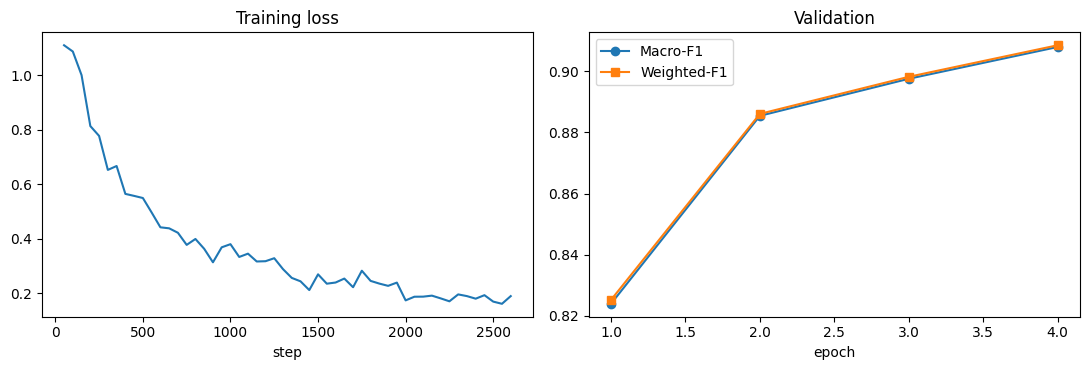

In [ ]:
# Đường cong huấn luyện
import matplotlib.pyplot as plt
log = pd.DataFrame(trainer.state.log_history)
ev = log.dropna(subset=["eval_macro_f1"])
tr = log.dropna(subset=["loss"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(tr["step"], tr["loss"]); ax[0].set_title("Training loss"); ax[0].set_xlabel("step")
ax[1].plot(ev["epoch"], ev["eval_macro_f1"], marker="o", label="Macro-F1")
ax[1].plot(ev["epoch"], ev["eval_weighted_f1"], marker="s", label="Weighted-F1")
ax[1].set_title("Validation"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{DRIVE_OUT_DIR}/training_curves.png", dpi=150); plt.show()

## 7. Dự đoán trên tập test & xuất `predictions.csv`

In [ ]:
pred_out = trainer.predict(test_ds)
y_true = pred_out.label_ids
y_pred = np.argmax(pred_out.predictions, axis=-1)

pred_df = pd.DataFrame({
    "id": test_df["id"],
    "text": test_df["text"],
    "ground_truth": [ID2LABEL[i] for i in y_true],
    "predicted_label": [ID2LABEL[i] for i in y_pred],
})
pred_path = f"{DRIVE_OUT_DIR}/predictions.csv"
pred_df.to_csv(pred_path, index=False, encoding="utf-8-sig")
print(" Đã lưu:", pred_path, "| số dòng:", len(pred_df))
pred_df.head(10)

 Đã lưu: /content/drive/MyDrive/ViRDC_PhoBERT/predictions.csv | số dòng: 3495


,id,text,ground_truth,predicted_label
0,0,đmn miền trung miền nam đánh parky,Discriminatory,Discriminatory
1,1,paky tụi bây,Discriminatory,Discriminatory
2,2,khứ nam bắc_thống đất dân_tộc việt_nam đoàn_kế...,Supportive,Supportive
3,3,coment parky đóng_góp cốc đồng_bào cali xôi cố,Discriminatory,Discriminatory
4,4,wel done,Other,Discriminatory
5,5,hai miền nam bắc tao nam người ta pk tức dùm,Supportive,Supportive
6,6,em miền bắc quý anh_em miền nam miền trung,Supportive,Supportive
7,7,namky hợp_tác với cali tôi nhốt chuồng kìa,Discriminatory,Discriminatory
8,8,không parky miền nam,Discriminatory,Discriminatory
9,9,giặc đánh dân tan_tác,Other,Discriminatory


## 8. Đánh giá: Macro-F1, Weighted-F1, Per-class F1, Confusion Matrix
- **Macro-F1**: trung bình đơn giản F1 của 3 lớp → phản ánh chất lượng trên cả lớp thiểu số  
- **Weighted-F1**: trung bình F1 có trọng số theo số mẫu mỗi lớp

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

labels_idx   = list(ID2LABEL.keys())
target_names = [ID2LABEL[i] for i in labels_idx]

mf1 = f1_score(y_true, y_pred, average="macro")
wf1 = f1_score(y_true, y_pred, average="weighted")
per_class = f1_score(y_true, y_pred, average=None, labels=labels_idx)
acc = accuracy_score(y_true, y_pred)

print(f"Accuracy    : {acc:.4f}")
print(f"Macro F1    : {mf1:.4f}")
print(f"Weighted F1 : {wf1:.4f}\n")
print(classification_report(y_true, y_pred, labels=labels_idx, target_names=target_names, digits=4))

res = {"accuracy": acc, "macro_f1": mf1, "weighted_f1": wf1,
       "per_class_f1": {n: float(v) for n, v in zip(target_names, per_class)},
       "config": {"model": MODEL_NAME, "max_length": MAX_LENGTH, "batch_size": BATCH_SIZE,
                  "epochs": NUM_EPOCHS, "lr": LR, "fp16": bool(args.fp16), "seed": SEED}}
with open(f"{DRIVE_OUT_DIR}/metrics.json", "w", encoding="utf-8") as f:
    json.dump(res, f, ensure_ascii=False, indent=2)

Accuracy    : 0.9082
Macro F1    : 0.9071
Weighted F1 : 0.9064

                precision    recall  f1-score   support

         Other     0.9413    0.7916    0.8600      1195
Discriminatory     0.8617    0.9429    0.9005      1156
    Supportive     0.9290    0.9948    0.9607      1144

      accuracy                         0.9082      3495
     macro avg     0.9106    0.9098    0.9071      3495
  weighted avg     0.9109    0.9082    0.9064      3495



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

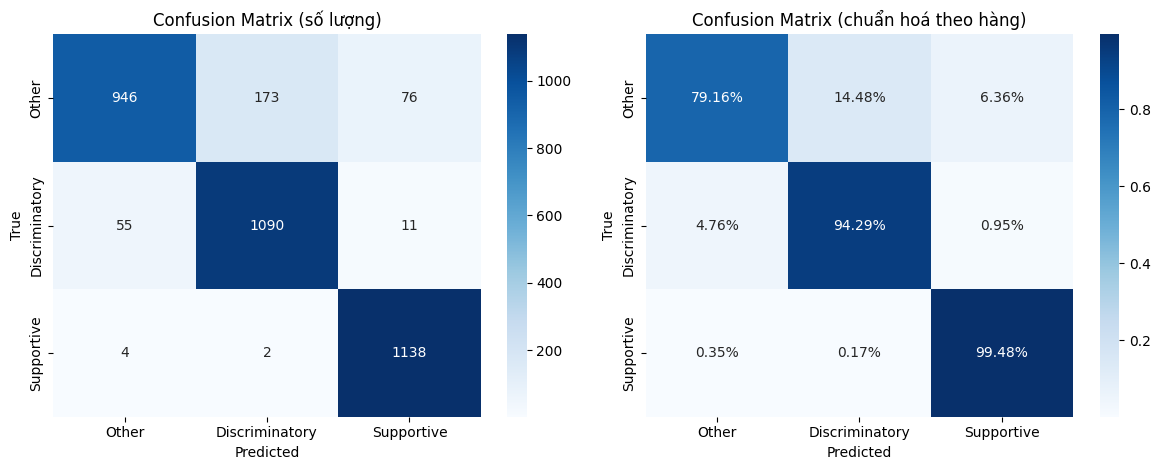

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=labels_idx)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=target_names, yticklabels=target_names, ax=ax[0])
ax[0].set_title("Confusion Matrix (số lượng)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True")
sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Blues", xticklabels=target_names, yticklabels=target_names, ax=ax[1])
ax[1].set_title("Confusion Matrix (chuẩn hoá theo hàng)"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("True")
plt.tight_layout(); plt.savefig(f"{DRIVE_OUT_DIR}/confusion_matrix.png", dpi=150); plt.show()

In [ ]:
# Bảng tổng hợp để chèn vào báo cáo + phân tích lỗi
summary = pd.DataFrame({"F1": list(per_class) + [mf1, wf1]},
                       index=target_names + ["Macro F1", "Weighted F1"]).round(4)
display(summary)
summary.to_csv(f"{DRIVE_OUT_DIR}/f1_summary.csv", encoding="utf-8-sig")

print("\n10 mẫu dự đoán sai:")
display(pred_df[pred_df.ground_truth != pred_df.predicted_label].head(10))

# (Tuỳ chọn) lưu model về Drive để tái sử dụng
# trainer.save_model(f"{DRIVE_OUT_DIR}/phobert_virdc"); tokenizer.save_pretrained(f"{DRIVE_OUT_DIR}/phobert_virdc")
print("\nFile trong thư mục kết quả:", os.listdir(DRIVE_OUT_DIR))

,F1
Other,0.8600
Discriminatory,0.9005
Supportive,0.9607
Macro F1,0.9071
Weighted F1,0.9064



10 mẫu dự đoán sai:


,id,text,ground_truth,predicted_label
4,4,wel done,Other,Discriminatory
9,9,giặc đánh dân tan_tác,Other,Discriminatory
21,21,công_ơn ta hi_sinh mảnh đất việt_nam tôi đời_đ...,Other,Supportive
22,22,hào ta người parky văn_minh,Other,Discriminatory
55,55,mấy bọn bình_luận parky khởi_nghĩa đi,Discriminatory,Other
67,67,tôi tưởng bọn gia_súc,Other,Discriminatory
78,78,parky,Other,Discriminatory
87,87,đừng hồ dạy,Other,Supportive
99,99,nhiên người ta ghét,Other,Discriminatory
109,109,cứu phân_biệt vùng miền,Other,Supportive



File trong thư mục kết quả: ['predictions.csv', 'metrics.json', 'confusion_matrix.png', 'f1_summary.csv', 'runs', 'training_curves.png']


In [ ]:
from scipy.special import softmax

def run(seed, lr, epochs=5, model_name="vinai/phobert-base"):
    set_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=NUM_LABELS, id2label=ID2LABEL, label2id=LABEL2ID)
    a = TrainingArguments(
        output_dir=f"/content/ckpt_{seed}_{lr}", num_train_epochs=epochs,
        per_device_train_batch_size=16, per_device_eval_batch_size=64,
        learning_rate=lr, warmup_steps=0.1, weight_decay=0.01, fp16=True,
        save_strategy="epoch", load_best_model_at_end=True,
        metric_for_best_model="macro_f1", save_total_limit=1,
        seed=seed, report_to="none", **{eval_key: "epoch"})
    t = Trainer(model=model, args=a, train_dataset=train_ds, eval_dataset=val_ds,
                data_collator=collator, compute_metrics=compute_metrics)
    t.train()
    val_f1 = t.evaluate()["eval_macro_f1"]
    return val_f1, t.predict(test_ds).predictions

results = []
# Chạy duy nhất 1 lần với lr = 2e-5 và seed = 42
lr = 2e-5
seed = 42
f1, test_logits = run(seed, lr)
results.append((f1, lr, seed, test_logits))
print(f"lr={lr} seed={seed} val Macro-F1={f1:.4f}")

# Lấy kết quả chạy duy nhất để đánh giá trên tập test
y_pred = test_logits.argmax(-1)
print("Test accuracy:", accuracy_score(y_true, y_pred))
print("Test Macro-F1:", f1_score(y_true, y_pred, average="macro"))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,0.797687,0.416478,0.834049,0.825928,0.827114
2,0.418864,0.332698,0.877253,0.875774,0.876419
3,0.299929,0.272032,0.906724,0.904011,0.904611
4,0.194964,0.277456,0.913877,0.911706,0.912242
5,0.167534,0.274404,0.921602,0.920056,0.920523


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Weighted F1
0.167534,0.274404,5,0.921602,0.920056,0.920523


lr=2e-05 seed=42 val Macro-F1=0.9201
Test accuracy: 0.9135908440629471
Test Macro-F1: 0.9128326480830977


=== KẾT QUẢ ENSEMBLE TRÊN TẬP TEST ===
Accuracy    : 0.9136
Macro F1    : 0.9128
Weighted F1 : 0.9122

                precision    recall  f1-score   support

         Other     0.9442    0.8075    0.8705      1195
Discriminatory     0.8651    0.9429    0.9023      1156
    Supportive     0.9382    0.9948    0.9656      1144

      accuracy                         0.9136      3495
     macro avg     0.9158    0.9151    0.9128      3495
  weighted avg     0.9161    0.9136    0.9122      3495

Đã lưu ảnh Confusion Matrix tại: /content/drive/MyDrive/ViRDC_PhoBERT/ensemble_confusion_matrix.png


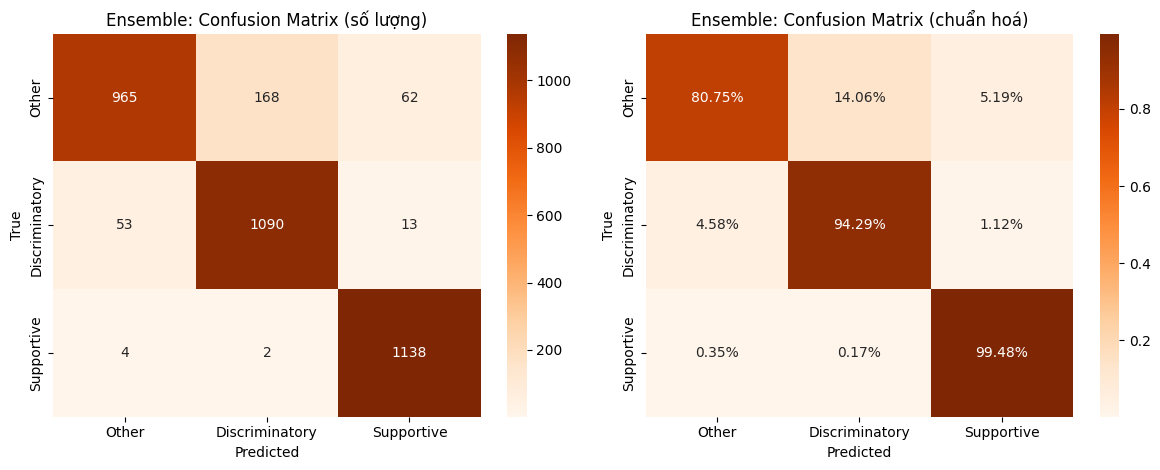

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Đánh giá kết quả Ensemble trên tập test
ensemble_acc = accuracy_score(y_true, y_pred)
ensemble_macro_f1 = f1_score(y_true, y_pred, average='macro')
ensemble_weighted_f1 = f1_score(y_true, y_pred, average='weighted')

print("=== KẾT QUẢ ENSEMBLE TRÊN TẬP TEST ===")
print(f"Accuracy    : {ensemble_acc:.4f}")
print(f"Macro F1    : {ensemble_macro_f1:.4f}")
print(f"Weighted F1 : {ensemble_weighted_f1:.4f}\n")

# In classification report chi tiết
target_names = [ID2LABEL[i] for i in sorted(ID2LABEL.keys())]
print(classification_report(y_true, y_pred, target_names=target_names, digits=4))

# Vẽ Confusion Matrix cho kết quả Ensemble
cm_ensemble = confusion_matrix(y_true, y_pred)
cm_ensemble_norm = cm_ensemble / cm_ensemble.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(cm_ensemble, annot=True, fmt="d", cmap="Oranges", xticklabels=target_names, yticklabels=target_names, ax=ax[0])
ax[0].set_title("Ensemble: Confusion Matrix (số lượng)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True")

sns.heatmap(cm_ensemble_norm, annot=True, fmt=".2%", cmap="Oranges", xticklabels=target_names, yticklabels=target_names, ax=ax[1])
ax[1].set_title("Ensemble: Confusion Matrix (chuẩn hoá)"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("True")
plt.tight_layout()

# Đường dẫn lưu file ảnh vào Google Drive
save_path = f"{DRIVE_OUT_DIR}/ensemble_confusion_matrix.png"
plt.savefig(save_path, dpi=150)
print(f"Đã lưu ảnh Confusion Matrix tại: {save_path}")

plt.show()

In [ ]:
import pandas as pd
from sklearn.metrics import classification_report

# Tạo classification report từ nhãn thực tế và nhãn dự đoán
report_dict = classification_report(y_true, y_pred, target_names=target_names, output_dict=True)

# Chuyển đổi báo cáo thành DataFrame
report_df = pd.DataFrame(report_dict).transpose().round(4)

# Xác định đường dẫn lưu file trên Google Drive
csv_save_path = f"{DRIVE_OUT_DIR}/test_classification_report.csv"
report_df.to_csv(csv_save_path, encoding="utf-8-sig")

print(f"Đã lưu bảng báo cáo kết quả thành công tại: {csv_save_path}")
display(report_df)

Đã lưu bảng báo cáo kết quả thành công tại: /content/drive/MyDrive/ViRDC_PhoBERT/test_classification_report.csv


,precision,recall,f1-score,support
Other,0.9442,0.8075,0.8705,1195.0000
Discriminatory,0.8651,0.9429,0.9023,1156.0000
Supportive,0.9382,0.9948,0.9656,1144.0000
accuracy,0.9136,0.9136,0.9136,0.9136
macro avg,0.9158,0.9151,0.9128,3495.0000
weighted avg,0.9161,0.9136,0.9122,3495.0000
